# OULAD — exploration

This notebook describes the hypothesis that risk varies with the course context. The figures come from functions in the `data_science` package; the features are not rewritten here. This week looks at the data and the features. The model is left to the following week. No classifier is trained.


## Data

The cell prints the shape of every table opened by `load_tables`. `studentVle` sits outside that function and is counted in pieces with the same type conversion. The cell also prints the archive checksum on record and the row unit. A row is one student's registration in one module presentation.


In [ ]:
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "data_science").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data_science.oulad.dataset import (
    AT_RISK_NEGATIVE,
    AT_RISK_POSITIVE,
    CUTOFF_DAY,
    FEATURE_LIST_PATH,
    PRESENTATION_ORDER,
    SPLIT_BY_PRESENTATION,
)
from data_science.oulad.download import ZIP_SHA256
from data_science.oulad.eda import (
    KEYS,
    LABELS_BY_LANG,
    LEFT_OUT_INFO,
    SPLIT_ORDER,
    bbb_zero_weight_summary,
    feature_modules,
    final_result_mapping,
    ggg_assessments,
    ggg_cutoff_summary,
    ggg_non_exam_in_window,
    hist_vs_current_points,
    load_features,
    missing_by_column,
    modules_without_scored_slot,
    print_rate_table,
    risk_extremes,
    risk_rate_pivot,
    sample_counts,
    signal_table,
    slot_means_table,
    sorted_feature_catalog,
    split_summary,
    student_vle_shape,
    table_shapes,
    train_rows,
)
from data_science.oulad.load import SOCIO_COLUMNS, load_tables

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
    }
)

MODULE_COLORS = {
    "AAA": "#4c78a8",
    "BBB": "#f58518",
    "CCC": "#e45756",
    "DDD": "#72b7b2",
    "EEE": "#54a24b",
    "FFF": "#eeca3b",
    "GGG": "#b279a2",
}


def plot_rate_bars(table, title, xlabel, ylabel):
    labels = table["bin"].astype(str).tolist()
    heights = table["at_risk_rate"].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(8.8, 4.6))
    ax.bar(labels, heights, color="#4c78a8", width=0.72)
    ax.set_ylim(0, 1.18)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    if any(len(label) > 4 for label in labels):
        ax.tick_params(axis="x", labelrotation=30)
        for tick in ax.get_xticklabels():
            tick.set_ha("right")
    for label, height, count in zip(labels, heights, table["n"].tolist()):
        if not np.isfinite(height):
            continue
        ax.text(label, height + 0.03, f"n={int(count)}", ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    plt.show()


tables = load_tables()
student_vle_rows, student_vle_cols = student_vle_shape()
features = load_features(tables)

print("zip_sha256", ZIP_SHA256)
for shape in table_shapes(tables, student_vle_rows, student_vle_cols):
    print(f"table={shape['table']} rows={shape['rows']} cols={shape['cols']}")
print("row_unit", "code_module,code_presentation,id_student")
print("feature_rows", len(features))
print("feature_cols", features.shape[1])
print("duplicate_row_keys", int(features.duplicated(KEYS).sum()))


zip_sha256 f2ed1902616c1fe8d2824d872c0b7d2d72be435bf0124d077044fe4be2c6d3e4
table=courses rows=22 cols=3
table=assessments rows=206 cols=6
table=vle rows=6364 cols=6
table=studentInfo rows=32593 cols=12
table=studentRegistration rows=32593 cols=5
table=studentAssessment rows=173912 cols=5
table=studentVle rows=10655280 cols=6
row_unit code_module,code_presentation,id_student
feature_rows 26403
feature_cols 26
duplicate_row_keys 0


In [2]:
LABELS = LABELS_BY_LANG["en"]


## Sample

Rows whose registration was removed before the cutoff day stay out of the sample. `at_risk` comes from `final_result`: Fail and Withdrawn are the at-risk class, and Pass and Distinction are not. The next cell prints the cutoff day, how many rows were removed, and that mapping.


In [3]:
info = tables["studentInfo"]
counts = sample_counts(tables)
print("cutoff_day", counts["cutoff_day"])
print("rows_before_cutoff_filter", counts["rows_before"])
print("rows_removed_before_cutoff", counts["rows_removed"])
print("rows_kept", counts["rows_kept"])
print("feature_rows", len(features))

print("at_risk_positive", " ".join(sorted(AT_RISK_POSITIVE)))
print("at_risk_negative", " ".join(sorted(AT_RISK_NEGATIVE)))
mapping = final_result_mapping(features, info)
print(mapping.to_string(index=False))


cutoff_day 60
rows_before_cutoff_filter 32593
rows_removed_before_cutoff 6190
rows_kept 26403
feature_rows 26403
at_risk_positive Fail Withdrawn
at_risk_negative Distinction Pass
final_result     n  at_risk_min  at_risk_max
 Distinction  3024            0            0
        Fail  7044            1            1
        Pass 12361            0            0
   Withdrawn  3974            1            1


## Split

Presentations are divided into `history`, `train`, and `test`. The table below prints, for each split, the row count, the at-risk rate, and the share of rows that have history.


In [4]:
print("split_by_presentation")
for presentation in PRESENTATION_ORDER:
    print(f"{presentation}={SPLIT_BY_PRESENTATION[presentation]}")

split_table = split_summary(features)
shown = split_table.rename(
    columns={
        "n_rows": LABELS["rows"],
        "at_risk_rate": LABELS["at_risk_rate"],
        "has_history_rate": LABELS["has_history_rate"],
    }
)
print(shown.to_string(index=False, float_format="{:.6f}".format))


split_by_presentation
2013B=history
2013J=train
2014B=train
2014J=test
  split  rows  at-risk rate  history rate
history  3927      0.466514      0.000000
  train 13639      0.425691      0.740597
   test  8837      0.382483      1.000000


## Course context

This section describes the course context. The at-risk rate is shown for each module and presentation, the earlier presentations' at-risk rate sits beside this presentation's rate, and the mean score of the same assignment slot is followed across presentations. The charts do not claim a cause; the rates are seen together.


### At-risk rate


code_presentation    2013B    2013J    2014B    2014J
code_module                                          
AAA                    NaN 0.234160      NaN 0.255882
BBB               0.448110 0.398766 0.417468 0.338691
CCC                    NaN      NaN 0.509615 0.456638
DDD               0.526462 0.470964 0.504654 0.438298
EEE                    NaN 0.326327 0.390785 0.313253
FFF               0.439427 0.426702 0.476800 0.373879
GGG                    NaN 0.355822 0.394937 0.362984


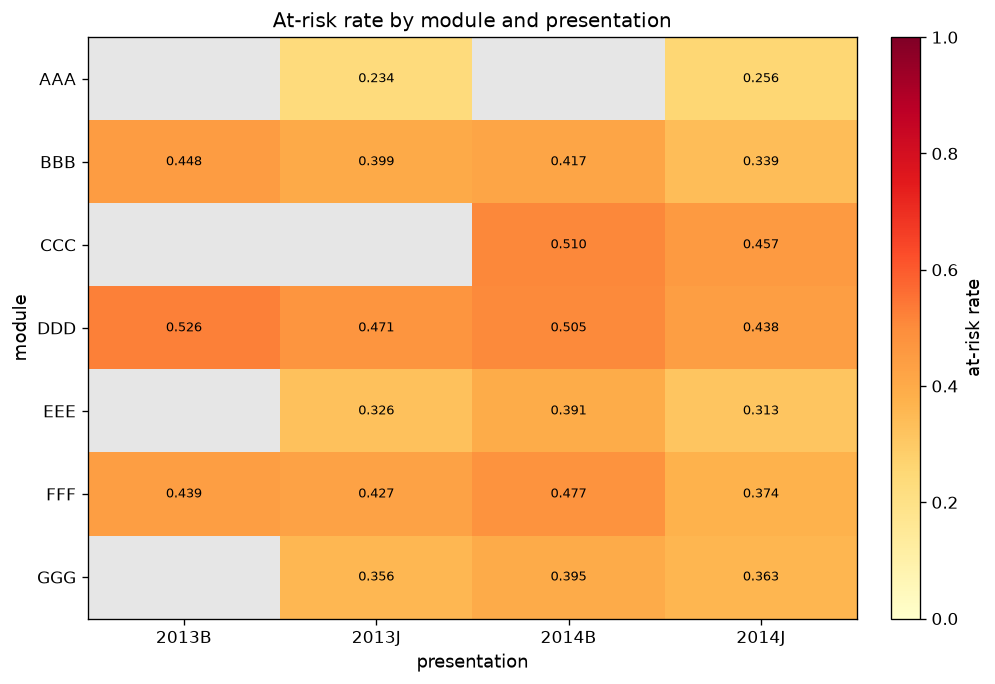

In [5]:
risk_rate = risk_rate_pivot(features)
print(risk_rate.to_string(float_format="{:.6f}".format))

values = risk_rate.to_numpy(dtype=float)
masked = np.ma.masked_invalid(values)
cmap = plt.cm.YlOrRd.copy()
cmap.set_bad("#e6e6e6")
fig, ax = plt.subplots(figsize=(8.4, 5.8))
image = ax.imshow(masked, cmap=cmap, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(risk_rate.shape[1]))
ax.set_yticks(range(risk_rate.shape[0]))
ax.set_xticklabels(list(risk_rate.columns))
ax.set_yticklabels(list(risk_rate.index))
ax.set_xlabel(LABELS["presentation"])
ax.set_ylabel(LABELS["module"])
ax.set_title(LABELS["heatmap_title"])
for row_index in range(values.shape[0]):
    for column_index in range(values.shape[1]):
        value = values[row_index, column_index]
        if not np.isfinite(value):
            continue
        ax.text(
            column_index,
            row_index,
            f"{value:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black",
        )
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04).set_label(LABELS["at_risk_rate"])
fig.tight_layout()
plt.show()


The heatmap shows the at-risk rate for each module and presentation together. A gray cell means that pair is not in the sample.


### Earlier risk rate


code_module code_presentation    n  at_risk_rate  hist_module_risk_rate
        AAA             2013J  363      0.234160                   <NA>
        AAA             2014J  340      0.255882               0.234160
        BBB             2013B 1455      0.448110                   <NA>
        BBB             2013J 1783      0.398766               0.448110
        BBB             2014B 1248      0.417468               0.420939
        BBB             2014J 1742      0.338691               0.419973
        CCC             2014B 1352      0.509615                   <NA>
        CCC             2014J 1868      0.456638               0.509615
        DDD             2013B 1077      0.526462                   <NA>
        DDD             2013J 1567      0.470964               0.526462
        DDD             2014B  967      0.504654               0.493570
        DDD             2014J 1410      0.438298               0.496538
        EEE             2013J  904      0.326327                

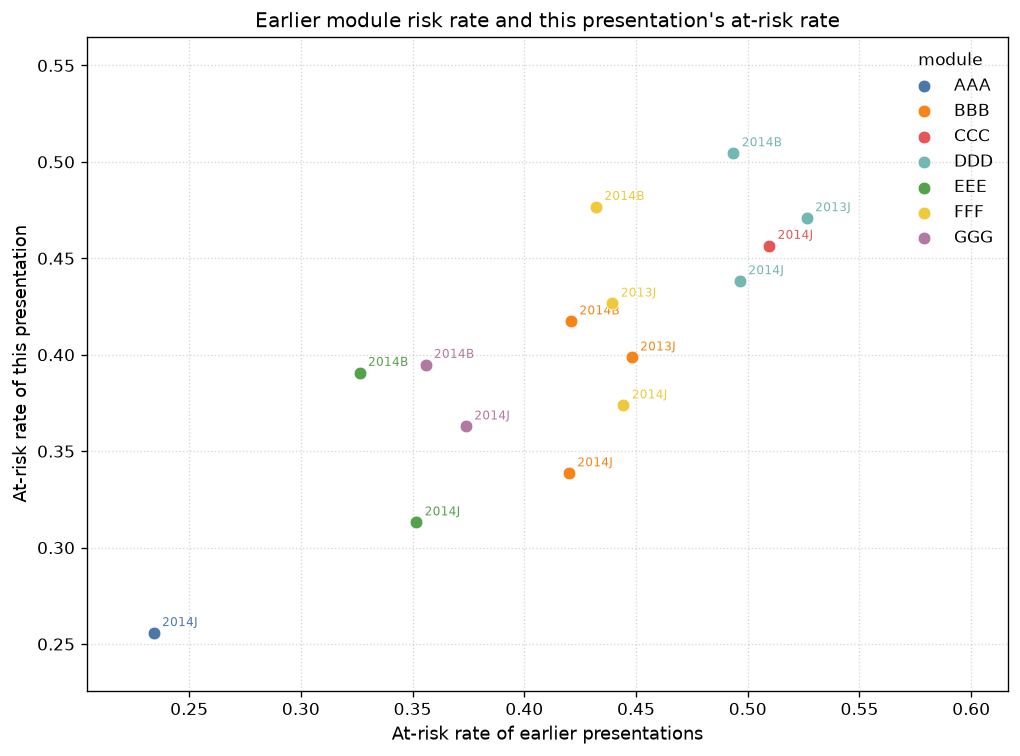

In [6]:
points = hist_vs_current_points(features)
print(
    points.drop(columns="pres_rank").to_string(index=False, float_format="{:.6f}".format)
)

plotted = points.loc[points["hist_module_risk_rate"].notna()].copy()
fig, ax = plt.subplots(figsize=(8.6, 6.4))
for module, color in MODULE_COLORS.items():
    part = plotted.loc[plotted["code_module"].eq(module)]
    if part.empty:
        continue
    ax.scatter(
        part["hist_module_risk_rate"].astype(float),
        part["at_risk_rate"].astype(float),
        s=58,
        color=color,
        label=module,
        zorder=3,
        linewidths=0.4,
        edgecolors="white",
    )
    for row in part.itertuples(index=False):
        ax.annotate(
            row.code_presentation,
            (float(row.hist_module_risk_rate), float(row.at_risk_rate)),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=7,
            color=color,
        )
x_values = plotted["hist_module_risk_rate"].astype(float)
y_values = plotted["at_risk_rate"].astype(float)
ax.set_xlim(float(x_values.min()) - 0.03, float(x_values.max()) + 0.09)
ax.set_ylim(float(y_values.min()) - 0.03, float(y_values.max()) + 0.06)
ax.set_xlabel(LABELS["scatter_xlabel"])
ax.set_ylabel(LABELS["scatter_ylabel"])
ax.set_title(LABELS["scatter_title"])
ax.set_axisbelow(True)
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(title=LABELS["module"], frameon=False)
fig.tight_layout()
plt.show()


Each point is a module presentation that has an earlier presentation. The point shows the earlier presentations' at-risk rate together with this presentation's at-risk rate, and color separates the modules.


### Slot score


code_module code_presentation assessment_type  slot    n  mean_score
        AAA             2013J             TMA     1  352   70.338068
        AAA             2013J             TMA     2  285   67.368421
        AAA             2014J             TMA     1  330   69.281818
        AAA             2014J             TMA     2  263   67.114068
        BBB             2013B             CMA     1 1182   93.874788
        BBB             2013B             TMA     1 1304   71.231595
        BBB             2013B             TMA     2 1149   70.421236
        BBB             2013J             CMA     1 1485   93.562290
        BBB             2013J             TMA     1 1652   71.994552
        BBB             2013J             TMA     2 1472   70.414402
        BBB             2014B             CMA     1 1049   93.860820
        BBB             2014B             TMA     1 1152   71.291667
        BBB             2014B             TMA     2 1071   71.515406
        BBB             2014J     

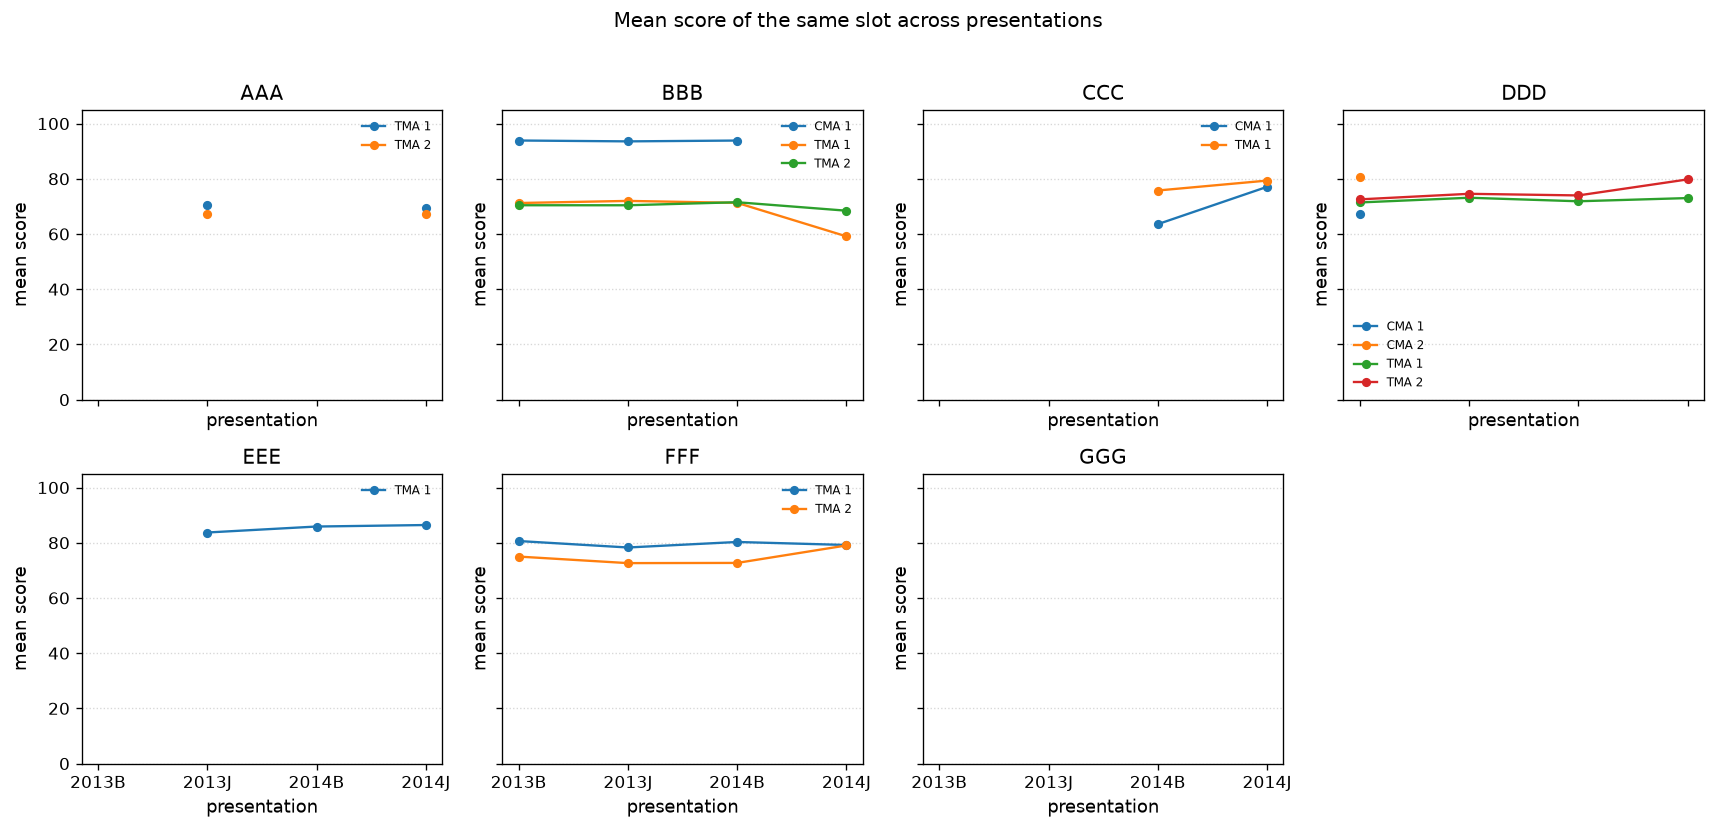

In [7]:
slot_means = slot_means_table(tables, features)
print(
    slot_means.drop(columns=["pres_rank", "slot_label"]).to_string(
        index=False,
        float_format="{:.6f}".format,
    )
)

modules = feature_modules(features)
missing_modules = modules_without_scored_slot(modules, slot_means)
print("modules_without_scored_slot", ",".join(missing_modules))

ncols = 4
nrows = int(np.ceil(len(modules) / ncols))
x_labels = list(PRESENTATION_ORDER)
x = np.arange(len(x_labels))
fig, axes = plt.subplots(nrows, ncols, figsize=(14.4, 3.5 * nrows), sharex=True, sharey=True)
axes_flat = np.atleast_1d(axes).ravel()
for ax, module in zip(axes_flat, modules):
    part = slot_means.loc[slot_means["code_module"].eq(module)]
    labels = list(dict.fromkeys(part["slot_label"].tolist()))
    for label in labels:
        series = part.loc[part["slot_label"].eq(label)].set_index("code_presentation")["mean_score"]
        y = series.reindex(x_labels).to_numpy(dtype=float)
        ax.plot(x, y, marker="o", linewidth=1.4, markersize=4.5, label=label)
    ax.set_title(LABELS["slot_title"].format(module=module))
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels)
    ax.set_xlabel(LABELS["slot_xlabel"])
    ax.set_ylabel(LABELS["slot_ylabel"])
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, linestyle=":", alpha=0.5)
    ax.set_ylim(0, 105)
    if labels:
        ax.legend(fontsize=7, frameon=False)
for ax in axes_flat[len(modules) :]:
    ax.set_visible(False)
fig.suptitle(LABELS["slot_suptitle"])
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()


Each panel draws, for one module, the mean score of the same assignment slot across presentations inside the cutoff window. A module with no such slot has no line.


## Early signals

This section uses only the training split. The unsubmitted-assessment count is followed value by value. Clicks, mean score, and the gap versus history are followed in bins. Each cell prints the at-risk rate and the row count of the bin.


### Unsubmitted assessments


split=train
rows 13639
bin     n  at_risk_rate
  0 11231      0.335322
  1  1506      0.774236
  2   701      0.964337
  3   201      0.985075


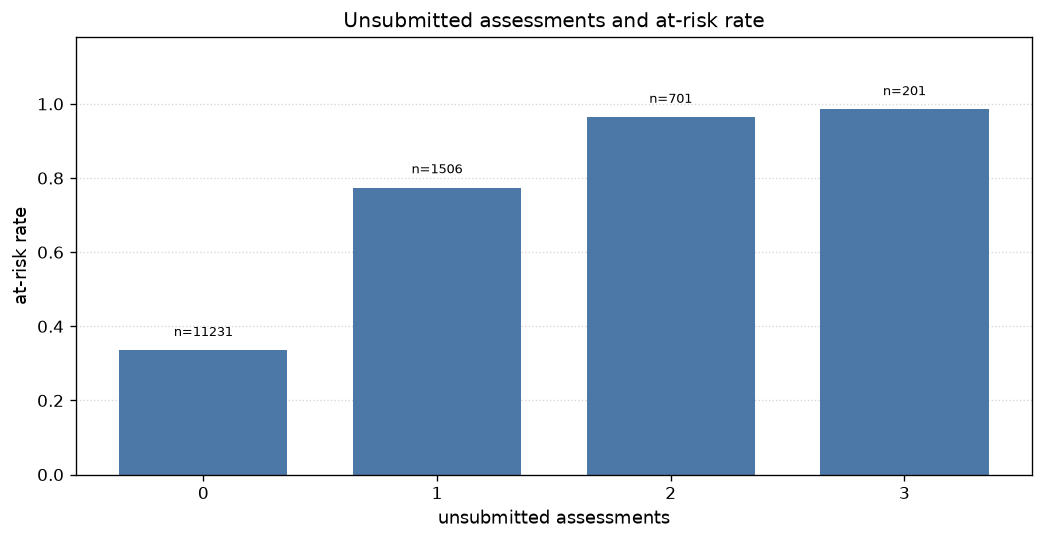

In [8]:
train = train_rows(features)
print("split=train")
print("rows", len(train))
unsubmitted_table = signal_table(train, "n_unsubmitted", LABELS["missing"])
print_rate_table(unsubmitted_table)
plot_rate_bars(
    unsubmitted_table,
    LABELS["unsubmitted_title"],
    LABELS["unsubmitted_xlabel"],
    LABELS["at_risk_rate"],
)


The bars show the unsubmitted-assessment count together with the at-risk rate in the training split.


### Clicks


split=train
rows 13639
              bin    n  at_risk_rate
   (-0.00, 94.00] 2735      0.644973
  (94.00, 244.00] 2732      0.499268
 (244.00, 454.00] 2719      0.429202
 (454.00, 842.40] 2725      0.339450
(842.40, 9921.00] 2728      0.214809


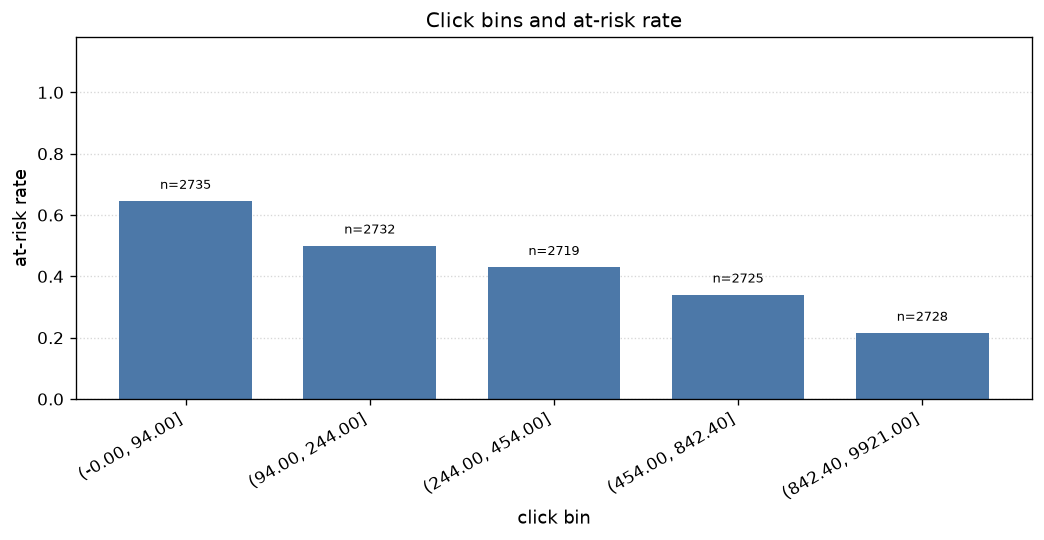

In [9]:
train = train_rows(features)
print("split=train")
print("rows", len(train))
clicks_table = signal_table(train, "vle_clicks", LABELS["missing"])
print_rate_table(clicks_table)
plot_rate_bars(
    clicks_table,
    LABELS["clicks_title"],
    LABELS["clicks_xlabel"],
    LABELS["at_risk_rate"],
)


The bars show click-count bins together with the at-risk rate in the training split.


### Mean score


split=train
rows 13639
            bin    n  at_risk_rate
 (-0.00, 65.00] 2327      0.722819
 (65.00, 75.00] 2230      0.459641
 (75.00, 81.67] 2109      0.325747
 (81.67, 88.00] 2282      0.246275
(88.00, 100.00] 2114      0.171712
        missing 2577      0.577028


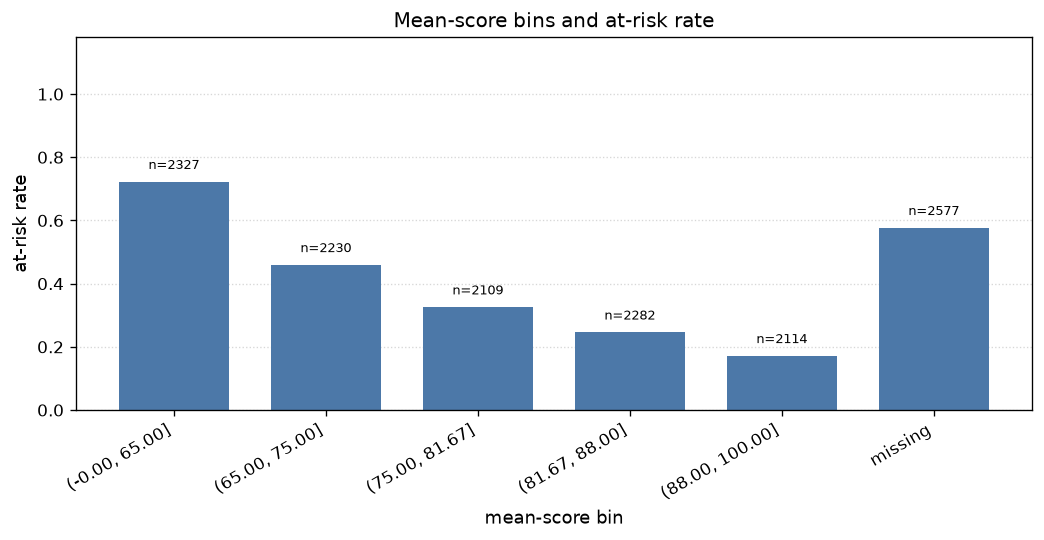

In [10]:
train = train_rows(features)
print("split=train")
print("rows", len(train))
score_table = signal_table(train, "score_mean", LABELS["missing"])
print_rate_table(score_table)
plot_rate_bars(
    score_table,
    LABELS["score_title"],
    LABELS["score_xlabel"],
    LABELS["at_risk_rate"],
)


The bars show mean-score bins together with the at-risk rate in the training split. Rows with an empty score sit in their own bin.


### Gap versus history


split=train
rows 13639
            bin    n  at_risk_rate
(-79.28, -9.93] 1734      0.724913
 (-9.93, -1.45] 1750      0.461143
  (-1.45, 4.51] 1711      0.357101
  (4.51, 10.19] 1737      0.261946
 (10.19, 26.54] 1724      0.190255
        missing 4983      0.471202


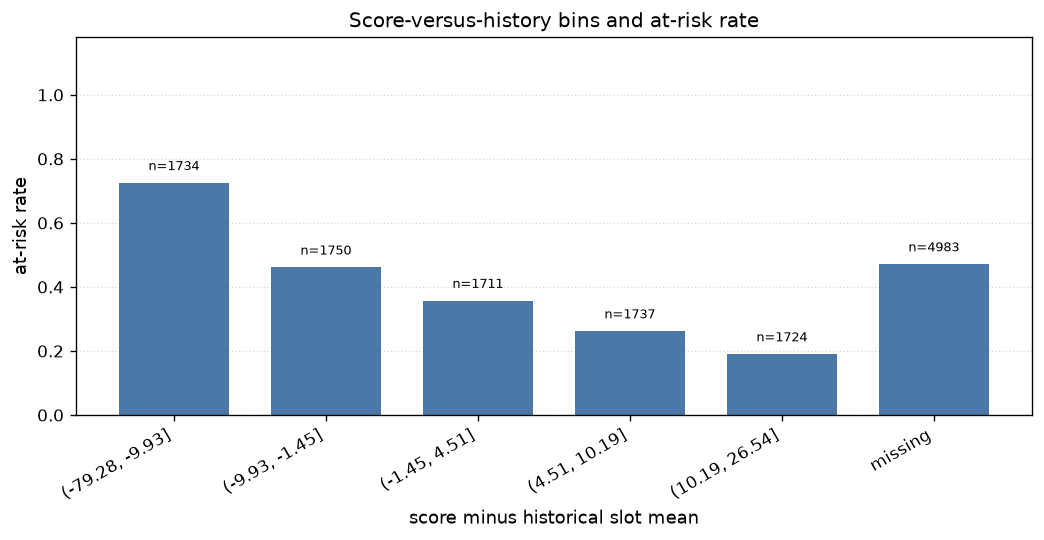

In [11]:
train = train_rows(features)
print("split=train")
print("rows", len(train))
gap_table = signal_table(train, "score_vs_hist", LABELS["missing"])
print_rate_table(gap_table)
plot_rate_bars(
    gap_table,
    LABELS["history_gap_title"],
    LABELS["history_gap_xlabel"],
    LABELS["at_risk_rate"],
)


The bars show the gap between a score and the historical slot mean together with the at-risk rate in the training split. Rows with an empty gap sit in their own bin.


## Data notes

Some presentations have no graded assessment by the cutoff day, while click records are still present. Some assessments have a weight of zero, and the weighted mean stays empty. The next cell prints both cases and the missing count of every column.


In [12]:
ggg_summary = ggg_cutoff_summary(features)
print("ggg_cutoff_window")
print(ggg_summary.to_string(index=False))

ggg_assessment_rows = ggg_assessments(tables)
print("ggg_non_exam_in_window", ggg_non_exam_in_window(ggg_assessment_rows))
print("ggg_assessments")
print(
    ggg_assessment_rows.loc[:, ["code_presentation", "assessment_type", "date", "weight"]]
    .sort_values(["code_presentation", "date", "assessment_type"], kind="mergesort")
    .to_string(index=False)
)

bbb = bbb_zero_weight_summary(tables, features)
print("bbb_2014j_assessments_in_window")
print(
    bbb["window"].loc[:, ["id_assessment", "assessment_type", "date", "weight"]].to_string(
        index=False
    )
)
print("bbb_2014j_zero_weight_tma")
print(
    bbb["zero_weight"].loc[:, ["id_assessment", "assessment_type", "date", "weight"]].to_string(
        index=False
    )
)
print("bbb_2014j_rows", bbb["rows"])
print("bbb_2014j_weighted_missing", bbb["weighted_missing"])
print("bbb_2014j_only_zero_weight_score", bbb["only_zero_weight_score"])
print(
    "bbb_2014j_only_zero_weight_and_weighted_missing",
    bbb["only_zero_weight_and_weighted_missing"],
)

missing = missing_by_column(features)
print("missing_by_column")
print(missing.to_string(index=False, float_format="{:.6f}".format))


ggg_cutoff_window
code_presentation  n_rows  n_expected_min  n_expected_max  score_mean_missing  vle_clicks_positive
            2014B     790               0               0                 790                  748
            2014J     697               0               0                 697                  657
ggg_non_exam_in_window 0
ggg_assessments
code_presentation assessment_type  date  weight
            2014B             TMA    61     0.0
            2014B             TMA   117     0.0
            2014B             TMA   166     0.0
            2014B             CMA   222     0.0
            2014B             CMA   222     0.0
            2014B             CMA   222     0.0
            2014B             CMA   222     0.0
            2014B             CMA   222     0.0
            2014B             CMA   222     0.0
            2014B            Exam   222   100.0
            2014J             TMA    61     0.0
            2014J             TMA   124     0.0
            2014J   

## Bridge to the school system

Each column in the feature list is tied to a grade, an attendance record, or the course context. Sociocultural columns are not used. The next cell prints the mapping table and shows that those columns are absent from the feature table.


In [13]:
catalog = sorted_feature_catalog(FEATURE_LIST_PATH)
shown = catalog.loc[:, ["column", "school_en"]].rename(
    columns={"column": LABELS["feature"], "school_en": LABELS["school"]}
)
print(shown.to_string(index=False))
print("sociocultural_columns")
for column in SOCIO_COLUMNS:
    print(f"{column}={column in features.columns}")
print("left_out_student_info")
for column in LEFT_OUT_INFO:
    print(f"{column}={column in features.columns}")


              feature                                    school counterpart
           score_mean                             Grade average (available)
  score_weighted_mean                             Grade average (available)
           delay_mean Assignment submission record (not in the school data)
             n_banked Assignment submission record (not in the school data)
           n_expected Assignment submission record (not in the school data)
          n_submitted Assignment submission record (not in the school data)
        n_unsubmitted Assignment submission record (not in the school data)
      vle_active_days                       Unexcused absence (approximate)
    vle_click_forumng                       Unexcused absence (approximate)
   vle_click_homepage                       Unexcused absence (approximate)
  vle_click_oucontent                       Unexcused absence (approximate)
   vle_click_resource                       Unexcused absence (approximate)
    vle_clic

## Limitations

The review is descriptive. Patterns seen together do not establish a cause. Withdrawn and Fail stay in the same risk class. The data come from a single institution.


In [14]:
print("OZET")
indexed = split_table.set_index("split")
for name in SPLIT_ORDER:
    row = indexed.loc[name]
    print(f"{name}_rows={int(row['n_rows'])}")
    print(f"{name}_at_risk_rate={float(row['at_risk_rate']):.6f}")
    print(f"{name}_has_history_rate={float(row['has_history_rate']):.6f}")

low, high = risk_extremes(risk_rate)
print(f"lowest_at_risk_module={low['code_module']}")
print(f"lowest_at_risk_presentation={low['code_presentation']}")
print(f"lowest_at_risk_rate={float(low['at_risk_rate']):.6f}")
print(f"highest_at_risk_module={high['code_module']}")
print(f"highest_at_risk_presentation={high['code_presentation']}")
print(f"highest_at_risk_rate={float(high['at_risk_rate']):.6f}")


OZET
history_rows=3927
history_at_risk_rate=0.466514
history_has_history_rate=0.000000
train_rows=13639
train_at_risk_rate=0.425691
train_has_history_rate=0.740597
test_rows=8837
test_at_risk_rate=0.382483
test_has_history_rate=1.000000
lowest_at_risk_module=AAA
lowest_at_risk_presentation=2013J
lowest_at_risk_rate=0.234160
highest_at_risk_module=DDD
highest_at_risk_presentation=2013B
highest_at_risk_rate=0.526462
